# Curso de Inteligencia Artificial

### <font color='purple'> Alumno: ____________________________</font>
### <font color='blue'> Profesor: Alejandro Ismael Trejo Castro</font>

El propósito de esta sesión es conocer como aplicar el modelo CRISP-DM en el análisis de datos, específicamente con un problema de clasificación (regresión logística), además de conocer funciones básicas de Python y el cómo resolver errores comunes en Python.

### <font color='red'> Entendimiento del negocio </font>

Dream Housing Finance (DHF) es una empresa dedicada a los préstamos hipotecarios. <br>

Una tarea importante para esta empresa es validar la elegibilidad del cliente para el préstamo antes de que pueda solicitarlo. A esta empresa le gustaría automatizar el proceso basándose en los datos proporcionados por el cliente al completar una solicitud.<br>

**Planteamiento del problema:** analizar los datos de clientes anteriores para predecir si un futuro solicitante es apto para un préstamo.<br>

**Motivación del problema:** trabajando con un algoritmo de predicción, se reducirán los casos de préstamos que no se hayan podido pagar.<br>

**Objetivos del proyecto:** identificar aquellas características con mayor poder predictivo. Encontrar un modelo de aprendizaje automático óptimo para clasificar si un cliente es elegible para un préstamo o no utilizando estas características predictivas.<br>

**Contexto de los datos:** DHF posee datos de sus operaciones anteriores. Los datos de los clientes son demográficos, como el sexo, el estado civil y la educación, entre otros, y características relacionadas con la economía, como los ingresos, el importe del préstamo y el historial crediticio.<br>

Algunos factores que la empresa cree que pueden afectar a la aprobación del préstamo son:
- <font color='blue'>*Salario*:</font> los solicitantes con ingresos elevados deberían tener más posibilidades de aprobación del préstamo.
- <font color='blue'>*Historial*: </font>los solicitantes que hayan pagado sus deudas anteriores deberían tener más posibilidades de que se les apruebe el préstamo.
- <font color='blue'>*Importe del préstamo*:</font> la aprobación del préstamo también debería depender del importe del préstamo. Si el importe del préstamo es menor, las posibilidades de aprobación del préstamo deberían ser altas.
- <font color='blue'>*Plazo del préstamo*: </font>un préstamo de menor duración y menor importe debería tener mayores posibilidades de aprobación.
- <font color='blue'>*Income per Term*:</font> cuanto menor sea la cantidad a pagar mensualmente para devolver el préstamo, mayores serán las posibilidades de aprobación del préstamo.

### <font color='red'> Entendimiento de los datos </font>

El conjunto de datos proporcionado por la empresa consta de 13 atributos y 614 filas.

A continuación se muestran las descripciones de los atributos.

- `Loan_ID` Este atributo es único y se refiere al ID del préstamo.
- `Gender` Este atributo tiene 2 valores (hombre o mujer).
- `Married` Este atributo tiene 2 valores (sí o no).
- `Dependents` Este atributo se refiere al número de personas que dependen económicamente del solicitante. Tiene 4 valores (0,1,2,+3).
- `Education` Este atributo tiene 2 valores (titulado o no titulado).
- `Self_Employed` Este atributo tiene 2 valores (sí o no).
- `ApplicantIncome` salario del solicitante.
- `CoapplicantIncome` salario del cosolicitante.
- `LoanAmount` importe total del préstamo solicitado.
- `Loan_Amount_Term` el tiempo en meses que tendrá el solicitante para devolver el préstamo.
- `Credit_History` se refiere al historial previo, si un solicitante pagó todas sus deudas tiene un valor de 1, en el otro caso será 0.
- `Property_Area` se refiere a la ubicación de la vivienda. Puede ser urbana, rural o semiurbana.
- `Loan_Status` es el atributo a clasificar y especifica si el préstamo fue concedido o no.

A partir de estos atributos, tenemos 12 variables independientes y una variable objetivo.<br>

Las 12 variables independientes pueden dividirse en características cualitativas y cuantitativas. <br>

Las **características cualitativas** son: Loan_ID, Gender, Married, Dependents, Education, Self_Employed y Property_Area. <br>

Las **características cuantitativas** son: ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term and Credit_History. Loan ID no servirá para el análisis.<br>

##### Funciones básicas para el análisis de datos en Python
- `NumPy` "Numerical Python" es una biblioteca que permite operaciones aritméticas/estadísticas, creación de vectores y matrices, así como operaciones de álgebra lineal
- `Pandas` "Panel Data" es una biblioteca especializada en la manipulación y el análisis de datos.
- `Seaborn` Es una biblioteca para crear gráficos estadísticos en python. Sugerido para código minimalista y creación rápida
- `Matplotlib` Es una biblioteca que también sirve para crear gráficos pero que ofrece más opciones de edición y un control más detallado en cada aspecto de la gráfica.

In [1]:
import warnings
# Ignorar todos los warnings
warnings.filterwarnings('ignore')

#Cargar bibliotecas esenciales para el análisis de datos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 1.26.4
pandas: 3.0.6
seaborn: 0.13.2
Matplotlib: 3.11.2


1. Importa los datos a tu ambiente de trabajo. Describe características de tu base de datos, imprimiendo información relevante en consola. Por ejemplo, cantidad de observaciones, cantidad de variables, tipo de variables, nombre de variables, etc. Asegúrate de que tus variables tengan un nombre fácilmente interpretable. En caso contrario, adjunta también un diccionario, un archivo .docx, .xlsx, .pdf, .csv, etc. donde se describa cada variable (por ejemplo: var1. Peso medido en gramos, var2. Diámetro medido en centímetros).


In [2]:
#Cargar la base de datos
df = pd.read_csv('loan.csv') 

#Mostrar 5 filas de datos al azar
df.sample(5, random_state=42)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
350,LP002139,Male,Yes,0,Graduate,No,9083,0.0,228.0,360.0,1.0,Semiurban,Y
377,LP002223,Male,Yes,0,Graduate,No,4310,0.0,130.0,360.0,NaN,Semiurban,Y
163,LP001570,Male,Yes,2,Graduate,No,4167,1447.0,158.0,360.0,1.0,Rural,Y
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
132,LP001478,Male,No,0,Graduate,No,2718,0.0,70.0,360.0,1.0,Semiurban,Y


In [3]:
# Cantidad de observaciones y columnas
df.shape

(614, 13)

In [4]:
# Información del dataset resumido
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [5]:
# Estadística decriptiva de variables cuantitativas
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [6]:
df['Credit_History'] = df['Credit_History'].astype('category')

In [7]:
# Estadística decriptiva de variables cualitativas
df.describe(include=['object', 'str', 'category'])

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Property_Area,Loan_Status
count,614,601,611,599,614,582,564.0,614,614
unique,614,2,2,4,2,2,2.0,3,2
top,LP001002,Male,Yes,0,Graduate,No,1.0,Semiurban,Y
freq,1,489,398,345,480,500,475.0,233,422


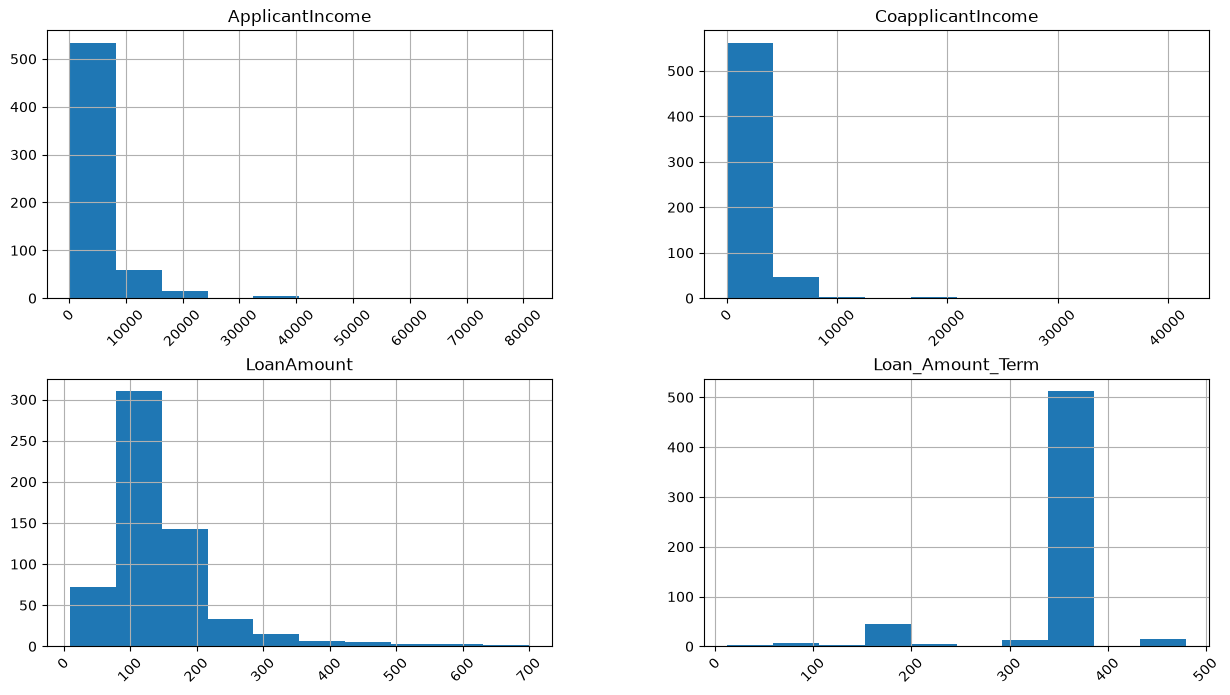

In [8]:
# Graficar cada variable cuantitativa
df.hist(figsize=(15,8), xrot=45)
plt.show()

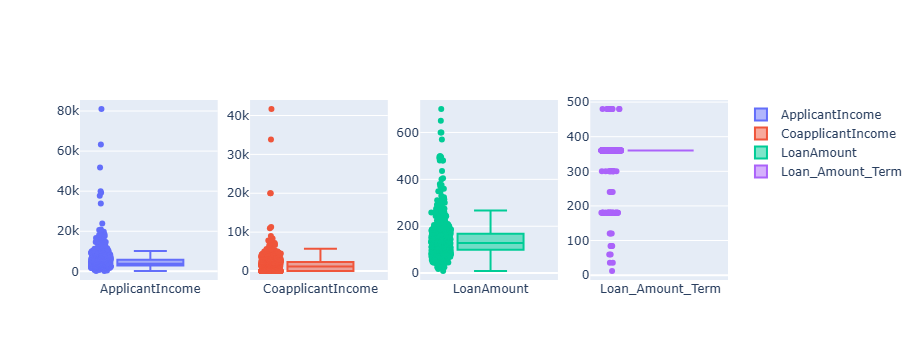

In [9]:
#Boxplots de las variables cuantitativas
from plotly.subplots import make_subplots
import plotly.graph_objects as go

vars = ['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']
fig = make_subplots(rows=1, cols=len(vars))
for i, var in enumerate(vars):
    fig.add_trace(
        go.Box(y=df[var],
        name=var),
        row=1, col=i+1
    )
fig.update_traces(boxpoints='all', jitter=.3)

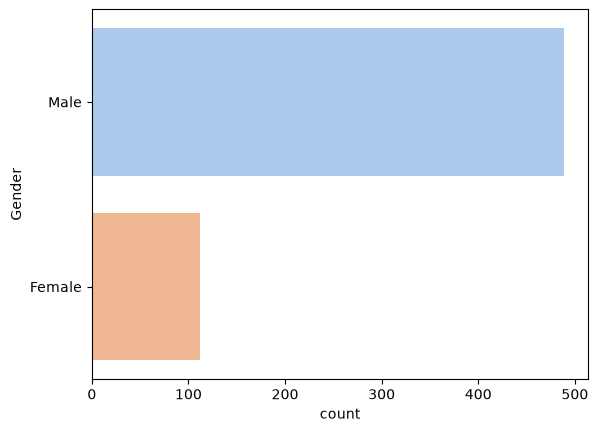

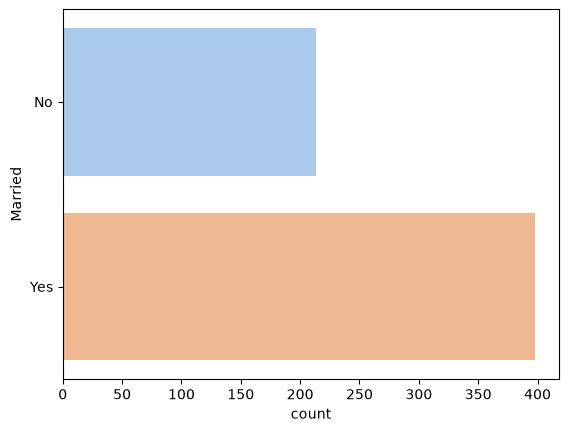

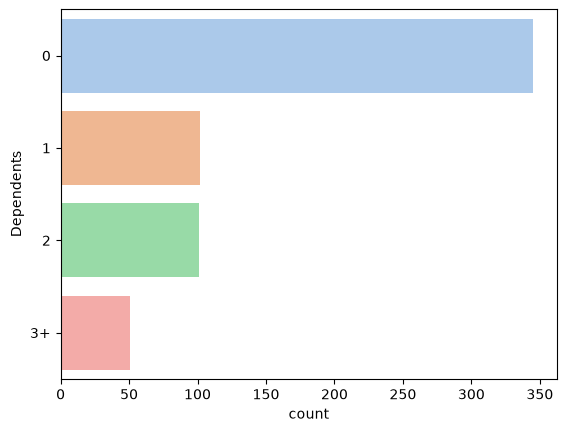

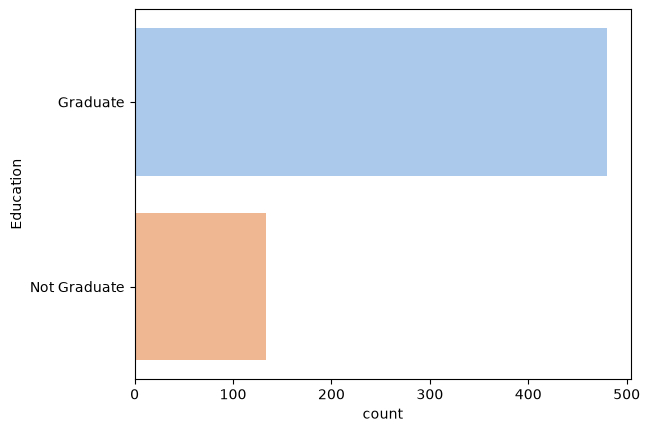

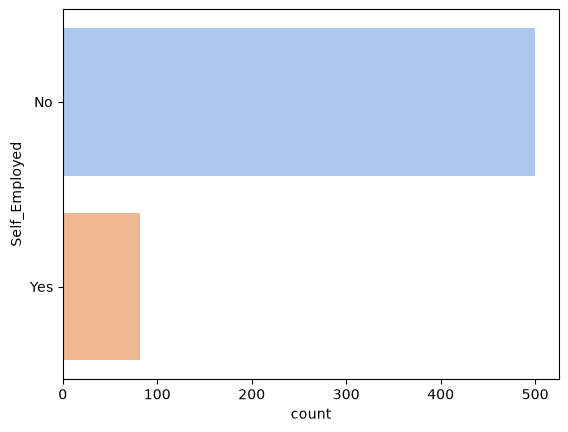

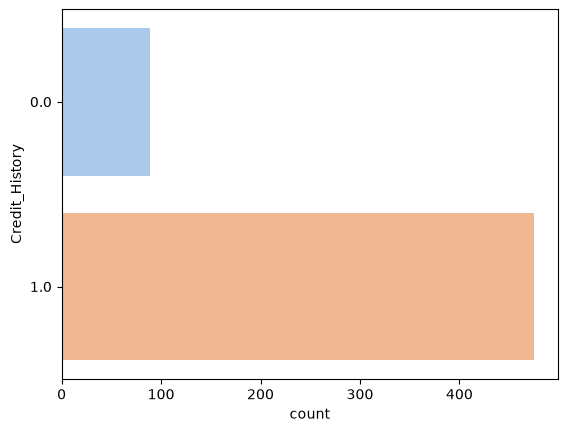

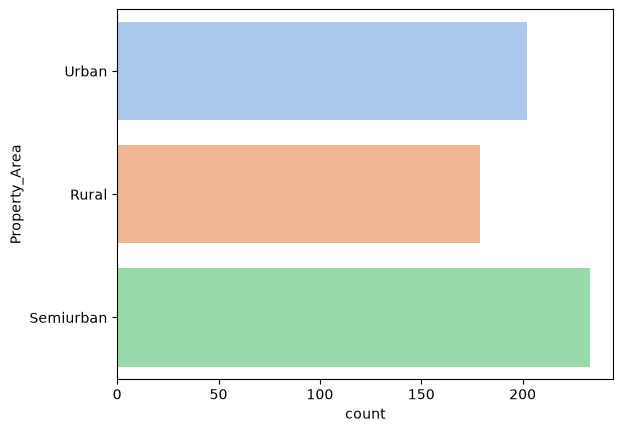

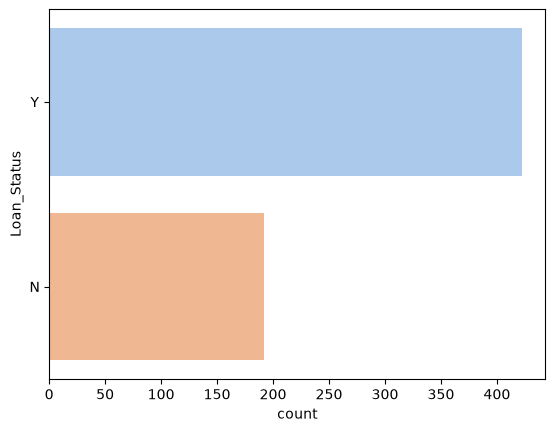

In [10]:
# Graficar cada variable cualitativa
for column in df.select_dtypes(include=['object', 'str', 'category']):
    if df[column].nunique() < 5:
        sns.countplot(y=column, data=df,palette="pastel")
        plt.show()

 <font color='blue'> Hay 614 préstamos o solicitudes únicos. Esperamos valores nulos ya que el recuento de las características restantes no completa 614. La mayoría de las solicitudes son de hombres (81%), casados (65%), sin personas a cargo (57%), titulados universitarios (78,17%), no autónomos (85%) y residencia semiurbana (37.95%). La característica objetivo tiene 422 casos de aceptación (69%). Ahora podemos eliminar la columna Loan_ID. Además la variable credit_history es dicotómica debemos cambiarla de tipo.</font><br>
    
 <font color='blue'>Al igual que las características cualitativas, faltan valores para LoanAmount, Loan_Amount_Term y Credit_History. Hay valores atípicos si se tiene en cuenta el valor máximo de ApplicantIncome y CoapplicantIncome. La mayoría de Credit_History refleja que los solicitantes pagaron sus deudas antes de solicitar un préstamo. El importe medio del préstamo solicitado a la empresa es de 146,41, no muy diferente de la mediana de 128. Podemos esperar debido a lo observado en la muestra que el máximo LoanAmount que se puede solicitar es de 700 y el plazo para pagar es de 40 años. </font>

### <font color='red'> Preparación de los datos </font>

Antes de empezar a crear modelos, debemos definir el conjunto de datos para la predicción. 

- Eliminar datos: Loan ID no nos sirve.

- Limpieza de datos: hay valores faltantes en nuestro conjunto de datos, con el fin de llenar estos valores faltantes, reemplazamos con la moda para las características cualitativas y con la mediana para las características cuantitativas. Ahora, podemos visualizar cada distribución o variable independiente con respecto al objetivo.

- Dar formato a los datos: las características categóricas que eran variables binarias se codificaron con etiquetas con valores de 0 y 1, mientras que las demás características categóricas se modificaron con variables ficticias. Después de este proceso tenemos 16 atributos independientes y 1 objetivo, cabe mencionar que previamente hemos eliminado Loan_ID. Los nuevos atributos son: Dependientes_0, Dependientes_1, Dependientes_2, Dependientes_3+, Propiedad_Area_Rural, Propiedad_Area_Semiurbana, Propiedad_Area_Urbana. Cambiar credit_history a variable object.

- Integración de datos: se crearon 4 variables más:
`LoanAmountLog:` el atributo que convierte en logarítmico el LoanAmount.
`TotalIncome:` el atributo que suma el ApllicantIncome y el Coapplicant Income.
`TotalIncomeLog:` la versión logarítmica de TotalIncome.
`EMI:` el importe que hay que pagar mensualmente para reembolsar el préstamo. Es el cociente entre TotalIncome y Loan_Amount_Term.

- Selección de características: con el fin de seleccionar las características más relevantes para la predicción del Importe_del_préstamo y la clasificación del Estado_del_préstamo, se realizó una matriz de correlaciones y 4 algoritmos de selección de características: Minimum Redundancy Maximum Relevance, selección univariante, eliminación recursiva de características e importancia de características formando un clasificador de árbol. 

2. Aplica soluciones para al menos dos de los cuatro problemas típicos que se describieron en el módulo 6 de este curso. Demuestra las modificaciones que se le realizaron a la base de datos imprimiendo en consola información relevante. Por ejemplo, para el caso de variables cualitativas, podrías imprimir la cantidad y los nombres de las variables antes de aplicar la solución, y la cantidad y los nombres de las variables después de aplicar la solución.

In [11]:
#Eliminar columna sin imprimir
df.set_index('Loan_ID', inplace=True)
#df = df.drop(['Loan_ID'], axis=1)

In [12]:
df['Credit_History'].value_counts(dropna=False)

Credit_History
 1.0    475
 0.0     89
NaN      50
Name: count, dtype: int64

In [13]:
# Diferenciar historial desconocido de historial negativo
df['Credit_History'] = (
    df['Credit_History']
    .cat.add_categories(['Desconocido'])
    .fillna('Desconocido')
)

df['Credit_History'].value_counts(dropna=False)

Credit_History
1.0            475
0.0             89
Desconocido     50
Name: count, dtype: int64

In [14]:
# Encontrar el número de valores faltantes
df.isnull().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [15]:
# Imputar valores cualitativos con el valor más frecuente (moda).
df['Gender'] = df['Gender'].fillna('Male')
df['Married'] = df['Married'].fillna('Yes')
df['Dependents'] = df['Dependents'].fillna('0')
df['Self_Employed'] = df['Self_Employed'].fillna('No')

In [16]:
# Imputar valores numéricos con la mediana
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term']=df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median())

In [17]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [18]:
# Revisar el status de mi variable objetivo o salida a clasificar
df['Loan_Status'].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

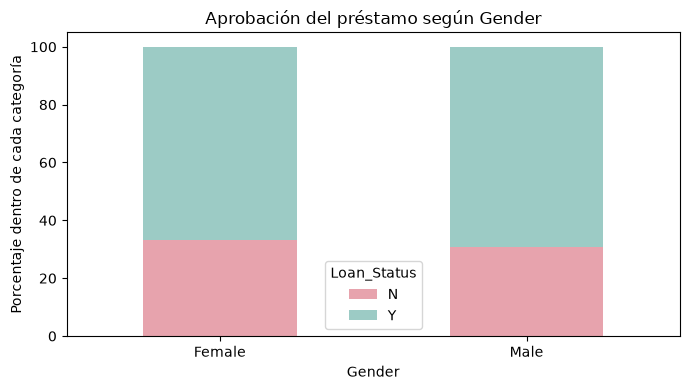

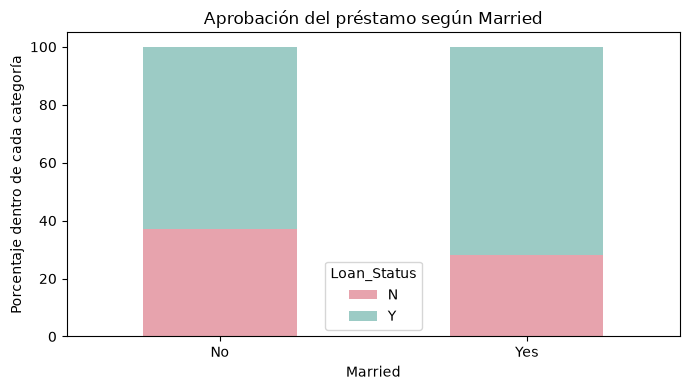

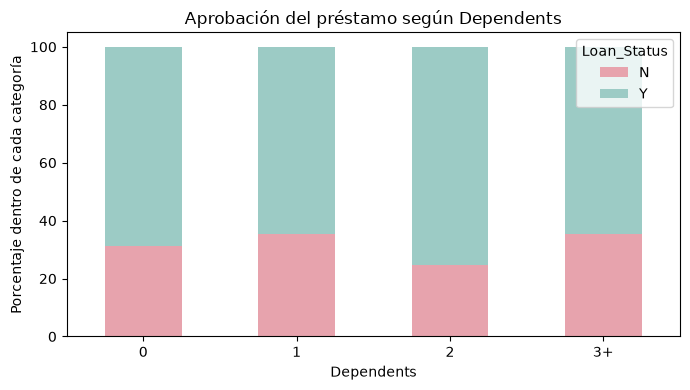

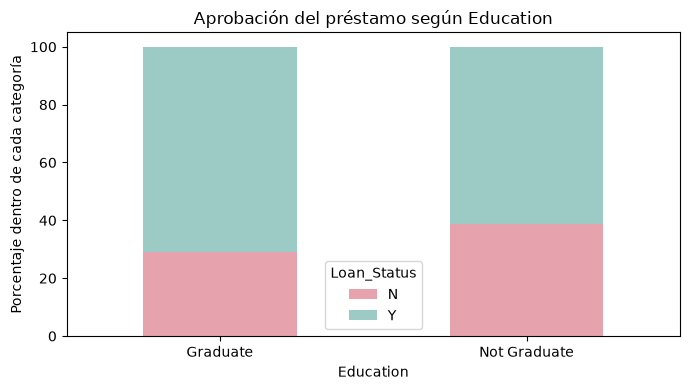

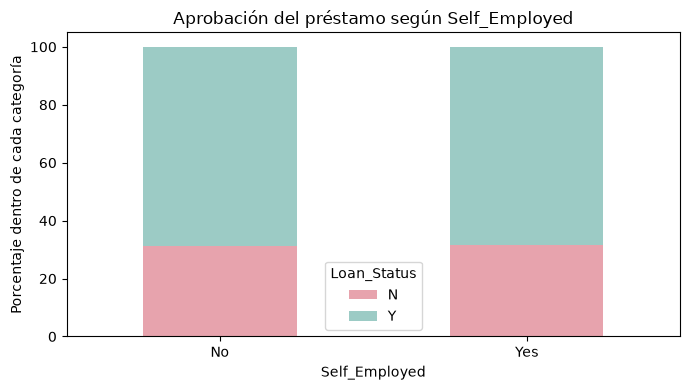

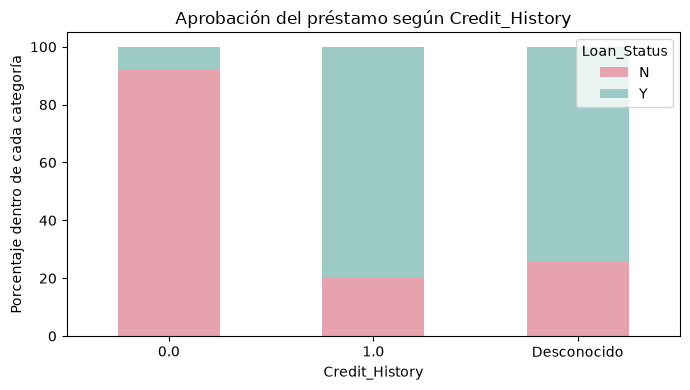

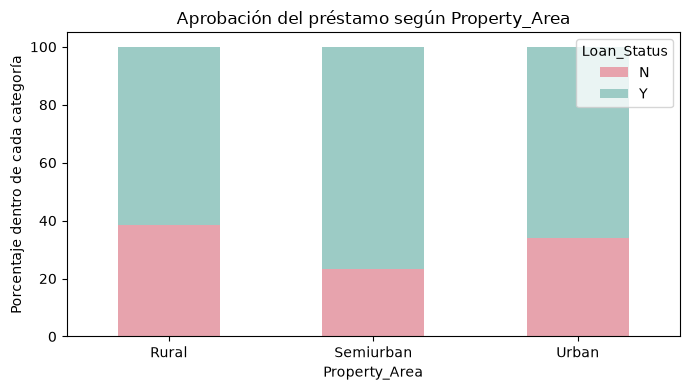

In [19]:
# Porcentaje de aprobaciones y no aprobaciones dentro de cada categoría
columnas_categoricas = df.select_dtypes(include=['object', 'str', 'category']).columns

for column in columnas_categoricas:
    if column != 'Loan_Status' and df[column].nunique() < 5:
        proporciones = pd.crosstab(
            df[column],
            df['Loan_Status'],
            normalize='index'
        ) * 100

        proporciones.plot(
            kind='bar',
            stacked=True,
            figsize=(7, 4),
            color=['#e7a3ad', '#9ccbc5']
        )

        plt.ylabel('Porcentaje dentro de cada categoría')
        plt.xlabel(column)
        plt.title(f'Aprobación del préstamo según {column}')
        plt.legend(title='Loan_Status')
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

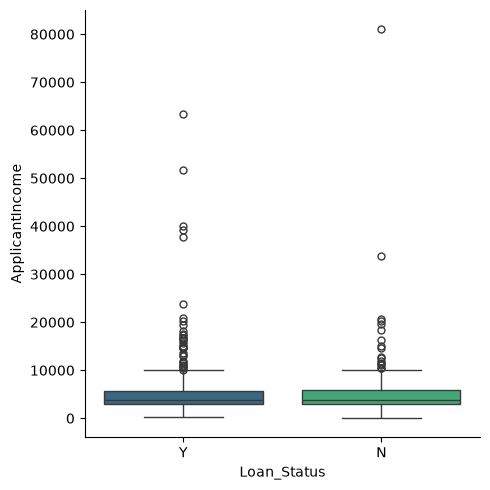

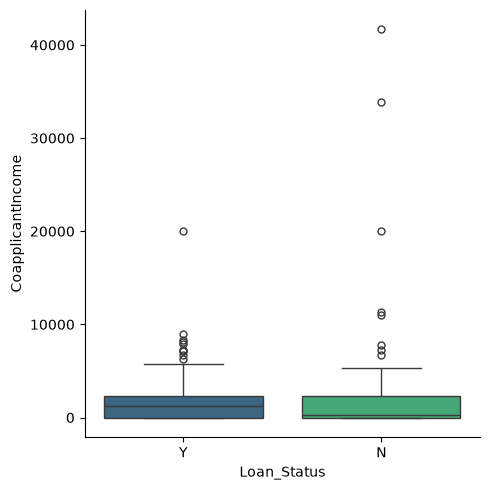

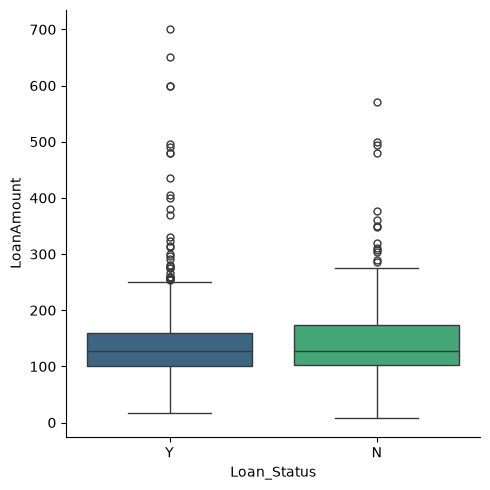

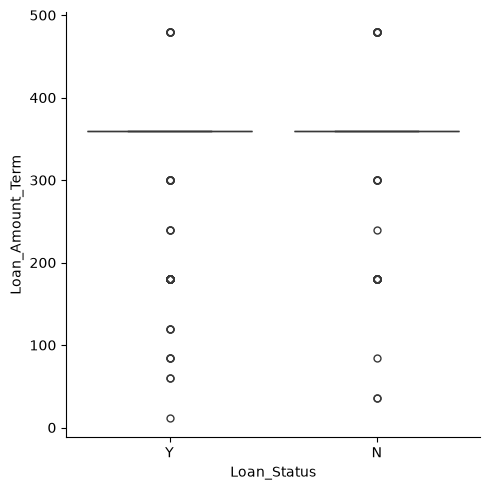

In [20]:
# Graficar cada variable cuantitativa a partir de la variable de salida
for column in df.select_dtypes(include=['int64','float64']):
    sns.catplot(x="Loan_Status", y=column, kind="box", dodge=False, data=df, palette="viridis")
    plt.show()

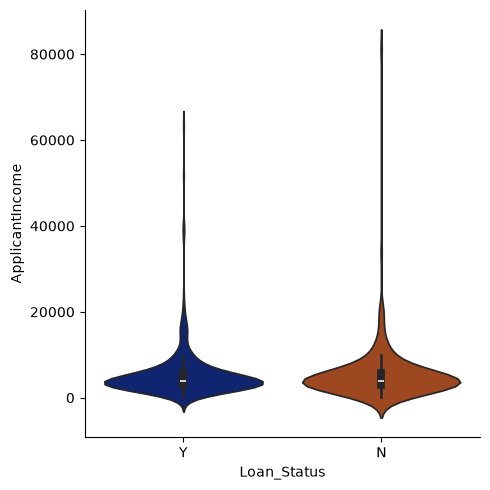

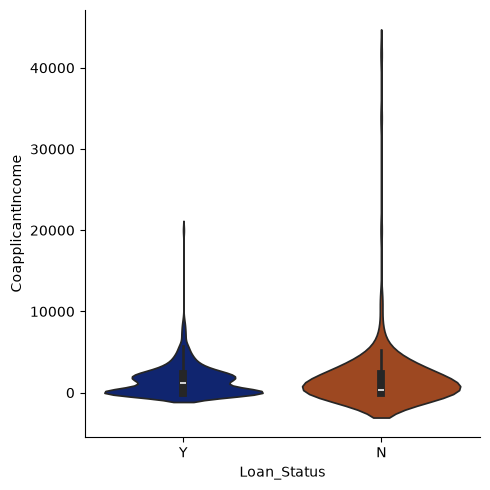

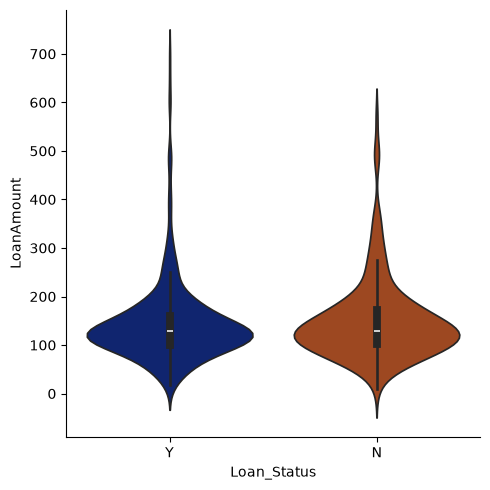

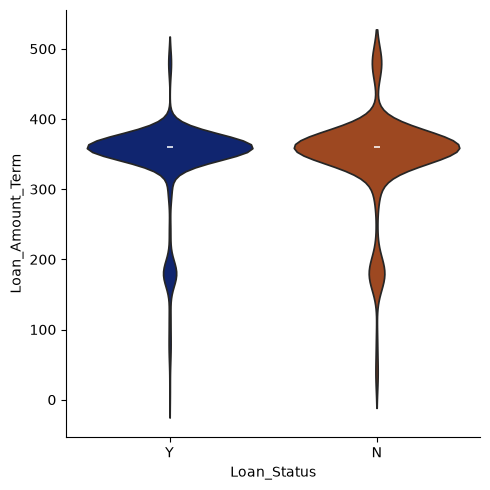

In [21]:
for column in df.select_dtypes(include=['int64','float64']):
    sns.catplot(x="Loan_Status", y=column, kind="violin", dodge=False, data=df,palette="dark")
    plt.show()

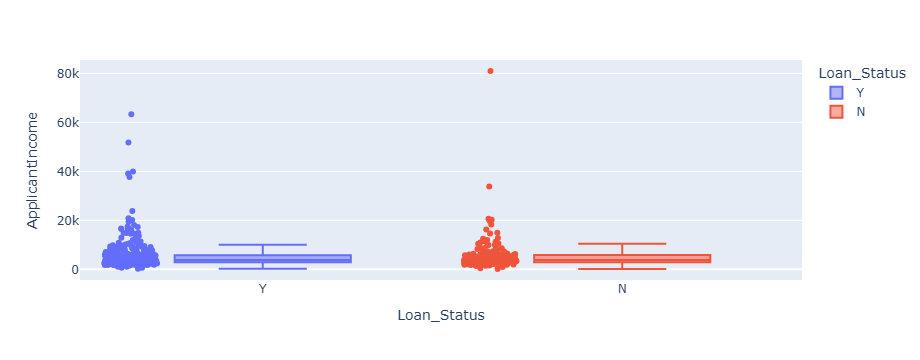

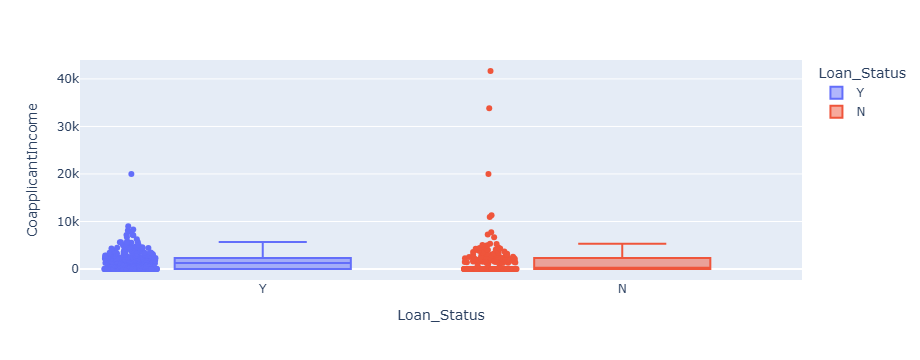

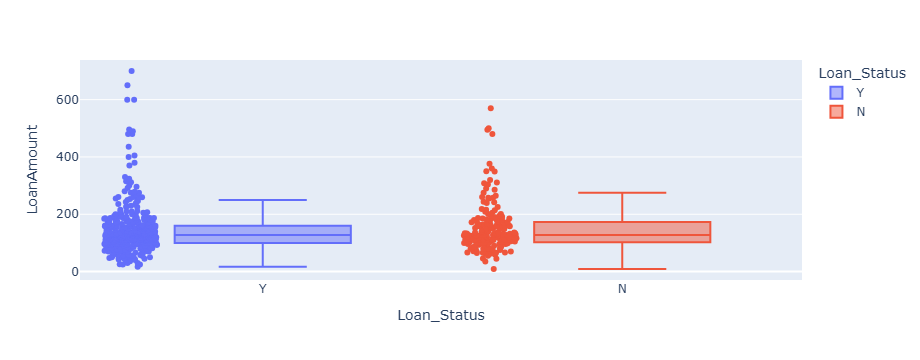

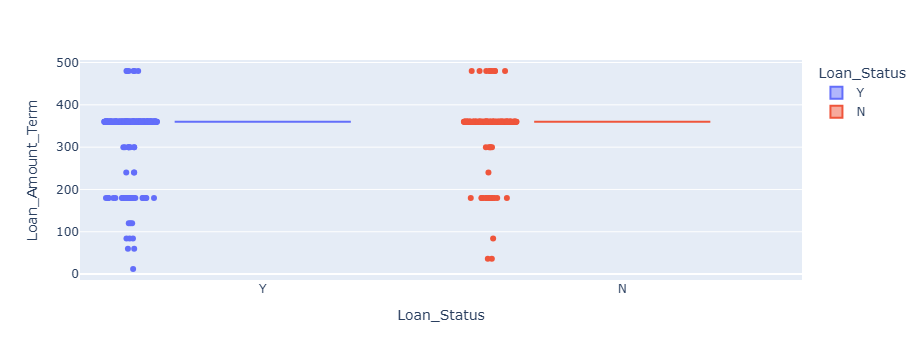

In [22]:
# Boxplots
import plotly.express as px

for column in df.select_dtypes(include=['int64','float64']):
    fig = px.box(
        data_frame=df,
        x="Loan_Status",
        y=column,
        points="all",
        color="Loan_Status",
        labels={"y": column}
    )
    fig.show()


In [ ]:
sns.set_theme(style="ticks")
sns.pairplot(df, hue="Loan_Status")
plt.show()

<font color='blue'>Podemos apreciar los gráficos de las características categóricas con respecto al objetivo. De esta imagen podemos deducir varias cosas. En el caso de la proporción de hombres y mujeres solicitantes es muy similar la distribución de préstamos aprobados y no aprobados. La proporción de solicitantes casados es mayor en los préstamos aprobados. El número de personas dependientes no parece ser relevante en la aprobación de un préstamo. Parece que en el caso de los licenciados hay una alta proporción de aprobación de préstamos. Además, los autónomos no son importantes y la proporción de préstamos aprobados en las residencias semiurbanas es mayor que en las rurales o urbanas.</font><br>

<font color='blue'>Podemos apreciar las características numéricas con respecto al objetivo. Los resultados son bastante sorprendentes, si se comparan con los factores que la empresa considera que pueden afectar a la aceptación de un préstamo. Por ejemplo, podemos ver que la distribución para los Ingresos del Solicitante es muy similar en ambos casos, préstamos aprobados y no aprobados. Lo mismo ocurre en Ingresos del Cosolicitante, Importe_Préstamo, Plazo_Importe_Préstamo. Al contrario podemos apreciar que el historial crediticio nos indica que si una persona tiene una puntuación crediticia perfecta hay más posibilidades de que le aprueben un préstamo. La importancia de las características con respecto al objetivo se validará mediante correlaciones y algoritmos de selección de características de aprobación de préstamos. Además, los autónomos no son importantes y la proporción de préstamos aprobados en las residencias semiurbanas es mayor que en las rurales o urbanas.</font><br>

In [23]:
# Codificación explícita de variables binarias
mapeos = {
    'Gender': {'Female': 0, 'Male': 1},
    'Married': {'No': 0, 'Yes': 1},
    'Education': {'Graduate': 0, 'Not Graduate': 1},
    'Self_Employed': {'No': 0, 'Yes': 1},
    'Loan_Status': {'N': 0, 'Y': 1}
}

for columna, mapa in mapeos.items():
    df[columna] = df[columna].map(mapa)

print(f'{len(mapeos)} columnas codificadas como binarias.')

5 columnas codificadas como binarias.


In [24]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,Urban,1
LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,Rural,0
LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,Urban,1
LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,Urban,1
LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,Urban,1


In [25]:
# Crear dummies
df = pd.get_dummies(df, drop_first=True)
df.columns

Index(['Gender', 'Married', 'Education', 'Self_Employed', 'ApplicantIncome',
       'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Loan_Status',
       'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Credit_History_1.0',
       'Credit_History_Desconocido', 'Property_Area_Semiurban',
       'Property_Area_Urban'],
      dtype='str')

In [26]:
df.info()

<class 'pandas.DataFrame'>
Index: 614 entries, LP001002 to LP002990
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      614 non-null    int64  
 1   Married                     614 non-null    int64  
 2   Education                   614 non-null    int64  
 3   Self_Employed               614 non-null    int64  
 4   ApplicantIncome             614 non-null    int64  
 5   CoapplicantIncome           614 non-null    float64
 6   LoanAmount                  614 non-null    float64
 7   Loan_Amount_Term            614 non-null    float64
 8   Loan_Status                 614 non-null    int64  
 9   Dependents_1                614 non-null    bool   
 10  Dependents_2                614 non-null    bool   
 11  Dependents_3+               614 non-null    bool   
 12  Credit_History_1.0          614 non-null    bool   
 13  Credit_History_Desconocido  614 non-nul

In [27]:
# Creación de nuevas variables
df['LoanAmountLog']=np.log(df['LoanAmount'])
df['TotalIncome']=df['ApplicantIncome']+df['CoapplicantIncome']
df['TotalIncomeLog']=np.log(df['TotalIncome'])
df['IncomePerTerm']=df['TotalIncome']/df['Loan_Amount_Term']

# Código para colocar Loan_Status como la columna final
df2=df.pop('Loan_Status')
df['Loan_Status']=df2
df.head()

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Dependents_1,Dependents_2,Dependents_3+,Credit_History_1.0,Credit_History_Desconocido,Property_Area_Semiurban,Property_Area_Urban,LoanAmountLog,TotalIncome,TotalIncomeLog,IncomePerTerm,Loan_Status
Loan_ID,,,,,,,,,,,,,,,,,,,,
LP001002,1,0,0,0,5849,0.0,128.0,360.0,False,False,False,True,False,False,True,4.852030,5849.0,8.674026,16.247222,1
LP001003,1,1,0,0,4583,1508.0,128.0,360.0,True,False,False,True,False,False,False,4.852030,6091.0,8.714568,16.919444,0
LP001005,1,1,0,1,3000,0.0,66.0,360.0,False,False,False,True,False,False,True,4.189655,3000.0,8.006368,8.333333,1
LP001006,1,1,1,0,2583,2358.0,120.0,360.0,False,False,False,True,False,False,True,4.787492,4941.0,8.505323,13.725000,1
LP001008,1,0,0,0,6000,0.0,141.0,360.0,False,False,False,True,False,False,True,4.948760,6000.0,8.699515,16.666667,1


In [28]:
# Identificar columnas Boolean
boolean_columns = df.select_dtypes(include='bool').columns

# Convertir columnas Boolean a Int
# True = 1
# False = 0
df[boolean_columns] = df[boolean_columns].astype(int)

In [29]:
df.head(10)

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Dependents_1,Dependents_2,Dependents_3+,Credit_History_1.0,Credit_History_Desconocido,Property_Area_Semiurban,Property_Area_Urban,LoanAmountLog,TotalIncome,TotalIncomeLog,IncomePerTerm,Loan_Status
Loan_ID,,,,,,,,,,,,,,,,,,,,
LP001002,1,0,0,0,5849,0.0,128.0,360.0,0,0,0,1,0,0,1,4.852030,5849.0,8.674026,16.247222,1
LP001003,1,1,0,0,4583,1508.0,128.0,360.0,1,0,0,1,0,0,0,4.852030,6091.0,8.714568,16.919444,0
LP001005,1,1,0,1,3000,0.0,66.0,360.0,0,0,0,1,0,0,1,4.189655,3000.0,8.006368,8.333333,1
LP001006,1,1,1,0,2583,2358.0,120.0,360.0,0,0,0,1,0,0,1,4.787492,4941.0,8.505323,13.725000,1
LP001008,1,0,0,0,6000,0.0,141.0,360.0,0,0,0,1,0,0,1,4.948760,6000.0,8.699515,16.666667,1
LP001011,1,1,0,1,5417,4196.0,267.0,360.0,0,1,0,1,0,0,1,5.587249,9613.0,9.170872,26.702778,1
LP001013,1,1,1,0,2333,1516.0,95.0,360.0,0,0,0,1,0,0,1,4.553877,3849.0,8.255569,10.691667,1
LP001014,1,1,0,0,3036,2504.0,158.0,360.0,0,0,1,0,0,1,0,5.062595,5540.0,8.619750,15.388889,0
LP001018,1,1,0,0,4006,1526.0,168.0,360.0,0,1,0,1,0,0,1,5.123964,5532.0,8.618305,15.366667,1


In [30]:
# Revisar el status de mi variable objetivo o salida a clasificar
df['Loan_Status'].value_counts()

Loan_Status
1    422
0    192
Name: count, dtype: int64

3. Realiza un proceso de selección de características. Puedes llevar a cabo una metodología de selección hacia adelante o eliminación hacia atrás, o incluso mezclarlas. También puedes utilizar un método de regularización. Evidencia tus resultados imprimiendo en consola la cantidad y los nombres de las variables antes y después del proceso de selección de características.

In [31]:
import sklearn
print("Scikit-learn:", sklearn.__version__) 

Scikit-learn: 1.9.1


In [32]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, stratify=df.Loan_Status ,train_size = 0.7, random_state=42)

X_train = train.drop('Loan_Status', axis = 1)
Y_train = train.Loan_Status
X_test = test.drop('Loan_Status', axis = 1)
Y_test = test.Loan_Status

# Imprime dimensiones de datos de entrenamiento
print("Train:", train.shape)
# Imprime dimensiones de datos de prueba
print("Test:",test.shape)

total_observations = train.shape[0] + test.shape[0]
print("Total de observaciones en ambos conjuntos:", total_observations)
print("Observaciones originales en el DataFrame:", df.shape[0])

Train: (429, 20)
Test: (185, 20)
Total de observaciones en ambos conjuntos: 614
Observaciones originales en el DataFrame: 614


In [33]:
Y_train.value_counts()

Loan_Status
1    295
0    134
Name: count, dtype: int64

In [34]:
Y_test.value_counts()

Loan_Status
1    127
0     58
Name: count, dtype: int64

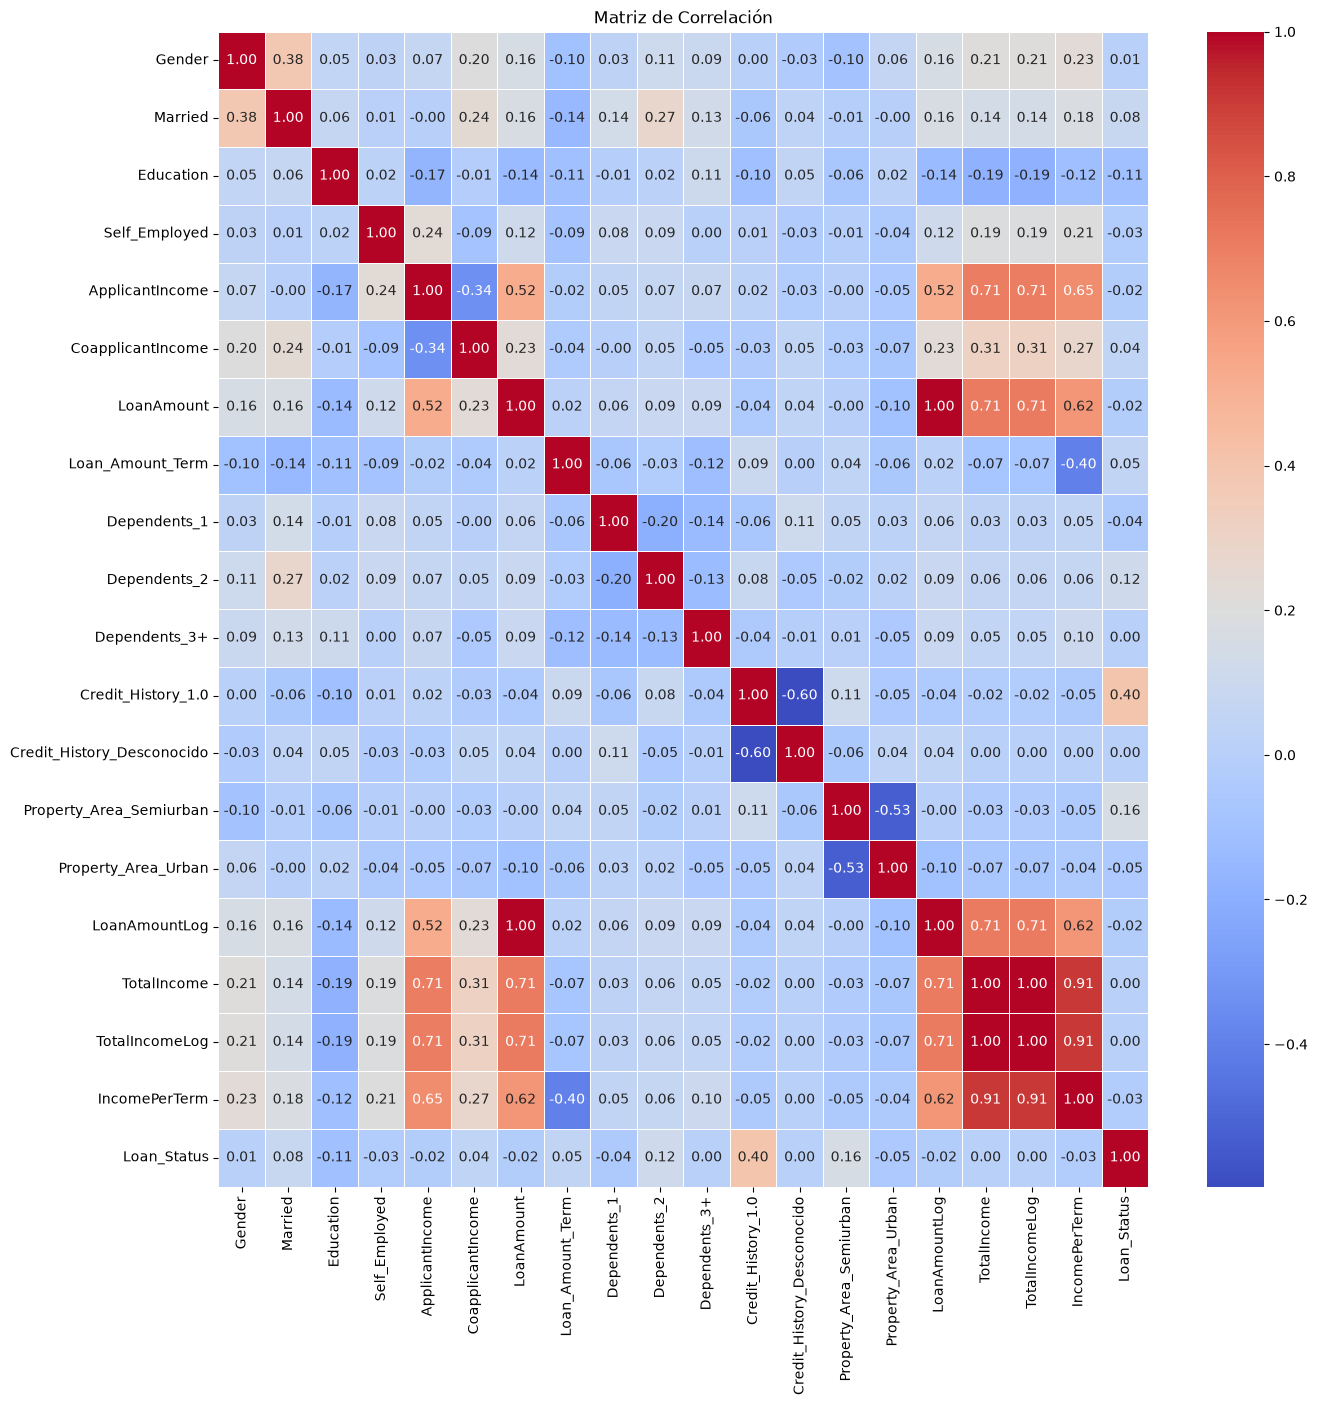

In [35]:
corrmat = train.corr(method = 'spearman')

# Crear el heatmap usando seaborn
plt.figure(figsize=(15, 15))
sns.heatmap(corrmat, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación')
plt.show()

<font color='blue'>Se puede apreciar la matriz de correlaciones. Para el objetivo, las características más correlacionadas son Credit_History (0.40) y Property_Area_Semiurban (0.16).</font><br>


#### mRMR

In [36]:
#!pip install feature-engine
from feature_engine.selection import MRMR
selector = MRMR(variables=None, method='MIQ', max_features=5)
selector.fit(X_train, Y_train)

selected_features = [col for col in X_train.columns if col not in selector.features_to_drop_]

print("Características seleccionadas:")
for i, feature in enumerate(selected_features):
    print(f"Posición {i+1}: {feature}")


Características seleccionadas:
Posición 1: Gender
Posición 2: ApplicantIncome
Posición 3: Loan_Amount_Term
Posición 4: Dependents_2
Posición 5: Credit_History_1.0


#### SelectKBest

In [37]:
# Análisis univariado

from numpy import set_printoptions
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif

# Extracción de características
selector = SelectKBest(f_classif, k=5)
selector.fit(X_train,Y_train)
# Obtener el score de las features
scores = selector.scores_

# Crear una lista de score-feature 
feature_scores = []
for i, score in enumerate(scores):
    feature_scores.append((score, X_train.columns[i]))

# Ordener features por score en orden descendiente)
feature_scores.sort(key=lambda x: x[0], reverse=True)

# Extraer el nombre del top 5 features
important_feature_names = [name for score, name in feature_scores[:5]]

print("Selected features in importance order:")
print(important_feature_names)

Selected features in importance order:
['Credit_History_1.0', 'Property_Area_Semiurban', 'Dependents_2', 'Education', 'Married']


In [38]:
# RFE Recursive feature elimination
# Feature Extraction with RFE
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Escalamiento para la selección basada en coeficientes
scaler_rfe = StandardScaler()

X_train_rfe = pd.DataFrame(
    scaler_rfe.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Selección de cinco características mediante RFE
model_rfe = LogisticRegression(
    solver='lbfgs',
    max_iter=5000,
    random_state=42
)

rfe = RFE(model_rfe, n_features_to_select=5)
rfe.fit(X_train_rfe, Y_train)

# Obtener los nombres de las columnas seleccionadas
selected_features_rfe = X_train_rfe.columns[rfe.support_].tolist()

print(f"Número de características seleccionadas: {len(selected_features_rfe)}")
print("\nColumnas que se quedan:")

for columna in selected_features_rfe:
    print(f"- {columna}")

Número de características seleccionadas: 5

Columnas que se quedan:
- Married
- Dependents_2
- Credit_History_1.0
- Credit_History_Desconocido
- Property_Area_Semiurban


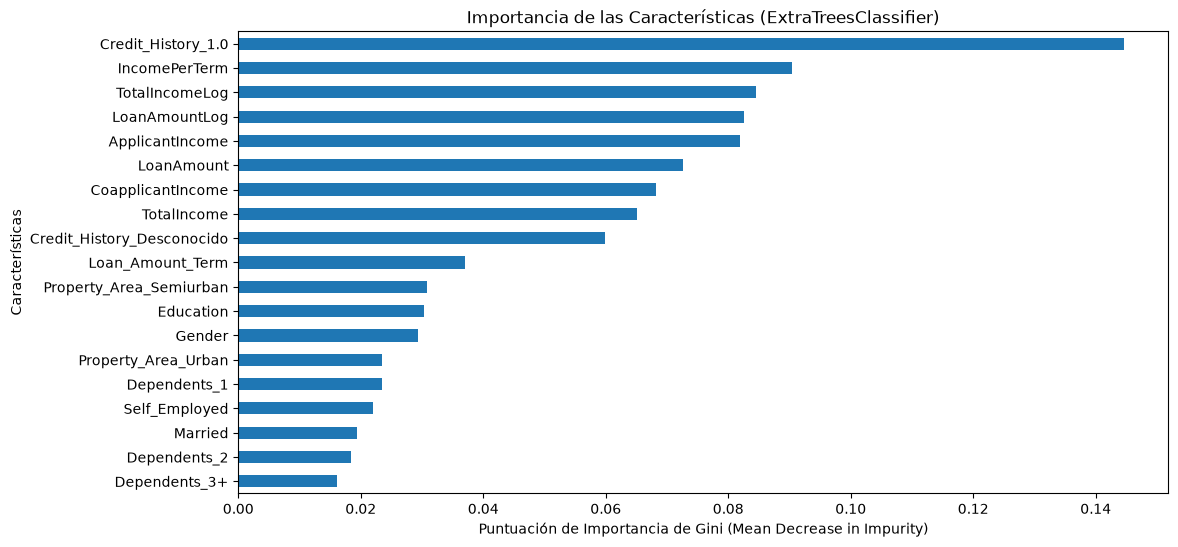

In [39]:
# Feature importance
from sklearn.ensemble import ExtraTreesClassifier
model = ExtraTreesClassifier(n_estimators=10, random_state=42)
model.fit(X_train,Y_train)
importances = model.feature_importances_
feature_names = X_train.columns 

# El resto del código funciona:
feature_importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(12, 6)) # Ajusta el tamaño del gráfico
feature_importance_series.plot(kind='barh') # Usar gráfico de barras horizontal para mejor legibilidad

plt.title("Importancia de las Características (ExtraTreesClassifier)")
plt.xlabel("Puntuación de Importancia de Gini (Mean Decrease in Impurity)")
plt.ylabel("Características")
plt.gca().invert_yaxis() # Invertir el eje Y para mostrar la más importante arriba
plt.show()

**La regresión logística es un modelo paramétrico que asume una relación lineal entre las variables independientes y el log-odds de la variable dependiente. Mientras que un árbol de decisión es un modelo no paramétrico que maneja bien relaciones no lineales y complejas sin requerir suposiciones específicas**

**La regresión logística es sensible a valores atípicos y multicolinealidad, requiere la conversión de variables categóricas a numéricas. Mientras que el árbol de decisión es menos sensible a valores atípicos; puede manejar variables categóricas directamente. Vale la pena comparar la interpretación y capacidad de rendimiento**


In [40]:
selected_features

['Gender',
 'ApplicantIncome',
 'Loan_Amount_Term',
 'Dependents_2',
 'Credit_History_1.0']

In [41]:
X_train = X_train[selected_features]
X_test = X_test[selected_features]

In [42]:
X_train.head()

,Gender,ApplicantIncome,Loan_Amount_Term,Dependents_2,Credit_History_1.0
Loan_ID,,,,,
LP001669,0,1907,360.0,0,1
LP001606,1,3497,360.0,0,1
LP002705,1,3775,360.0,0,1
LP001520,1,4860,360.0,0,1
LP002625,1,3583,360.0,0,1


### <font color='red'> Modelado </font>

Para los modelos de predicción de Loan_Status se utilizó el algoritmo de regresión logística. El conjunto de datos se dividió en entrenamiento y prueba, y el 30% de los datos se asignó a la prueba. Se utilizará un modelado con 10-FOLD Cross Validation. Los modelos se estratificaron para mantener las proporciones de clases mediante estratificación. Se utilizará la métrica de accuracy para seleccionar los mejores parámetros. ROC AUC, recall, precision y f1 se utilizarán también en el despligue para ver el desempeño del modelo en la prueba.

4. Genera un modelo de regresión lineal, no lineal, o logística para caracterizar y/o predecir una variable de interés. El tipo de regresión dependerá del tipo de variable de respuesta, así como de su relación con las variables de entrada. El modelo deberá entrenarse en un subconjunto de los datos que represente el 70% de las observaciones totales. Imprime en consola los coeficientes estimados al entrenar el modelo, e indica para cuáles de ellos puedes afirmar que existe una asociación significativa con la respuesta.


In [43]:
# Búsqueda Hiperparámetros
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = [
    # Solvers generales (multiclase) con l2/none
    {'solver': ['lbfgs', 'newton-cg', 'sag'],
     'penalty': ['l2', 'none'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    # liblinear (binario), l1 o l2
    {'solver': ['liblinear'],
     'penalty': ['l1', 'l2'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    # saga: l1, l2, elasticnet (requiere l1_ratio)
    {'solver': ['saga'],
     'penalty': ['l1', 'l2'],
     'C': [100, 10, 1.0, 0.1, 0.01],
     'max_iter': [1000, 2000]},
    {'solver': ['saga'],
     'penalty': ['elasticnet'],
     'l1_ratio': [0.2, 0.5, 0.8],
     'C': [1.0, 0.1],
     'max_iter': [1000, 2000]},
]

grid_search = GridSearchCV(LogisticRegression(random_state=42, class_weight="balanced"), param_grid = param_grid, scoring='accuracy', cv=10, n_jobs=-1, refit=True)
grid_search.fit(X_train,Y_train)

print ("Mean cross-validated score of the best_estimator: {}".format (grid_search.best_score_))
print ("best parameters: {}".format (grid_search.best_params_))
print ("best estimator: {}".format (grid_search.best_estimator_))

best = grid_search.best_estimator_  
y1 = best.predict(X_test)

Mean cross-validated score of the best_estimator: 0.7529346622369879
best parameters: {'C': 1.0, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'liblinear'}
best estimator: LogisticRegression(class_weight='balanced', max_iter=1000, penalty='l1',
                   random_state=42, solver='liblinear')


In [44]:
model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, penalty='l1',
                   random_state=42, solver='liblinear').fit(X_train,Y_train)

y2 = model.predict(X_test)
print(np.array_equal(y1, y2))  # True esperado

True


De acuerdo al 10-fold cross validation. El mejor modelo es la regresión logística con los siguientes parámetros
 
- C=1 Inverse of regularization strength; must be a positive float. Like in support vector machines, smaller values specify stronger regularization.
- max_iter=1000 Maximum number of iterations taken for the solvers to converge.
- penalty='l1' add a L1 penalty term;
- solver='liblinear' For multiclass problems, only ‘newton-cg’, ‘sag’, ‘saga’ and ‘lbfgs’ handle multinomial loss;

Este modelo tuvo un promedio de accuracy de validación cruzada en los 10 modelos de 0.76 lo que nos indicá que clasifica en promedio con un 76% de exactitud. 

### <font color='red'> Evaluación </font>

5. Genera predicciones para el 30% de datos que no se utilizaron para entrenar al modelo. A partir de dichas predicciones, calcula el residual standard error y la R cuadrada (si se resolvió un problema de regresión), o la exactitud (si se resolvió un problema de clasificación). Imprime en consola los resultados y agrega un comentario que describa en palabras sencillas el significado de los mismos.

In [45]:
# Scikit learn modules for Model Evaluation & Improvement
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.metrics import classification_report
from sklearn.metrics import auc, roc_auc_score, roc_curve

In [46]:
acc = accuracy_score(Y_test, y2)
prec = precision_score(Y_test, y2, pos_label=1)
rec = recall_score(Y_test, y2, pos_label=1)
f1 = f1_score(Y_test, y2, pos_label=1)

print("Accuracy", acc)
print("Precision", prec)
print("Recall", rec)
print("F1-score", f1)

Accuracy 0.8
Precision 0.8214285714285714
Recall 0.905511811023622
F1-score 0.8614232209737828


AUC (modelo seleccionado): 0.7607


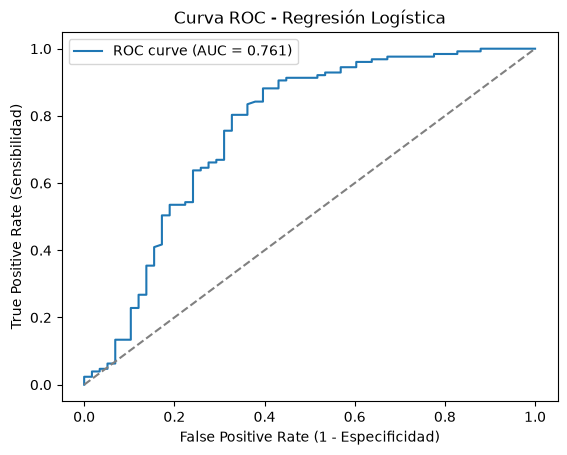

In [47]:
y_proba = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(Y_test, y_proba)
print(f"AUC (modelo seleccionado): {auc:.4f}")

fpr, tpr, thresholds = roc_curve(Y_test, y_proba)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate (1 - Especificidad)')
plt.ylabel('True Positive Rate (Sensibilidad)')
plt.title('Curva ROC - Regresión Logística')
plt.legend()
plt.show()

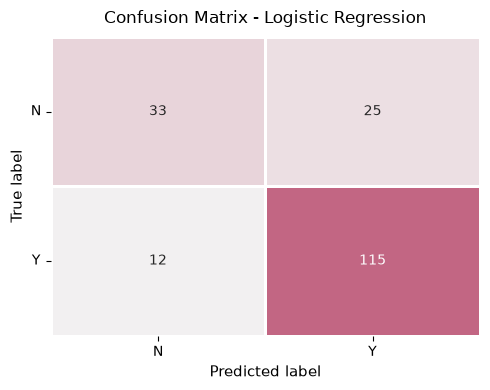

In [48]:
cm = confusion_matrix(Y_test, y2, labels=[0, 1])
labels_cute = ['N', 'Y']

plt.style.use('default')  # quitamos estilos raros
fig, ax = plt.subplots(figsize=(5, 4))

# paleta pastel tipo tus plots
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=sns.light_palette("#c26683", as_cmap=True),  # pastel verdoso
    cbar=False,
    linewidths=1,
    linecolor='white',
    xticklabels=labels_cute,
    yticklabels=labels_cute,
    ax=ax
)

ax.set_xlabel("Predicted label", fontsize=11)
ax.set_ylabel("True label", fontsize=11)
ax.set_title("Confusion Matrix - Logistic Regression", fontsize=12, pad=10)

# que se vean rectos
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()


In [49]:
print(classification_report(Y_test, y2, target_names=labels_cute))


results = pd.DataFrame(
    [['LR', acc, prec, rec, f1, auc]],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']
)
print(results)

              precision    recall  f1-score   support

           N       0.73      0.57      0.64        58
           Y       0.82      0.91      0.86       127

    accuracy                           0.80       185
   macro avg       0.78      0.74      0.75       185
weighted avg       0.79      0.80      0.79       185

  Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
0    LR       0.8   0.821429  0.905512  0.861423  0.760657


#### Desempeño general del modelo:

AUC = 0.76, accuracy = 0.80, precision = 0.82, recall clase positiva = 0.91, F1 = 0.86

- El AUC (0.76) significa que, al comparar una solicitud aprobada y una no aprobada elegidas al azar, el modelo asigna una puntuación mayor a la aprobada aproximadamente el 76% de las veces.

- La exactitud (80 %) sugiere que 8 de cada 10 predicciones fueron correctas.

- El recall (91 %) es relativamente alto, lo que significa que el modelo detecta casi todos los casos aprobados (positivos reales). Esto es clave, porque en un contexto bancario es preferible identificar correctamente a los buenos clientes, incluso si se cometen algunos falsos positivos.

#### SHAP SHapley Additive exPlanation

In [50]:
#!pip install shap
import shap

# Crear un objeto explainer
explainer = shap.LinearExplainer(model, X_train)

# Calcular los valores SHAP
shap_values = explainer.shap_values(X_test)


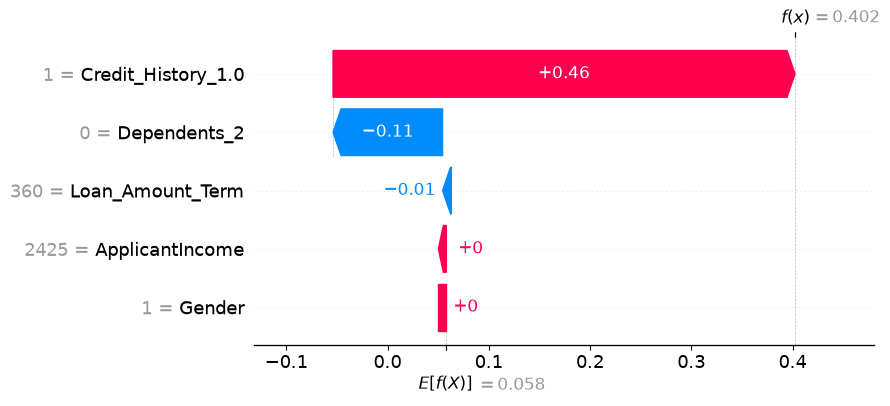

In [51]:
# Ver cómo decidió el algoritmo para la primera prueba
instance_index = 0
shap.waterfall_plot(shap.Explanation(values=shap_values[instance_index], 
                                     base_values=explainer.expected_value, 
                                     data=X_test.iloc[instance_index], 
                                     feature_names=X_test.columns.tolist()))


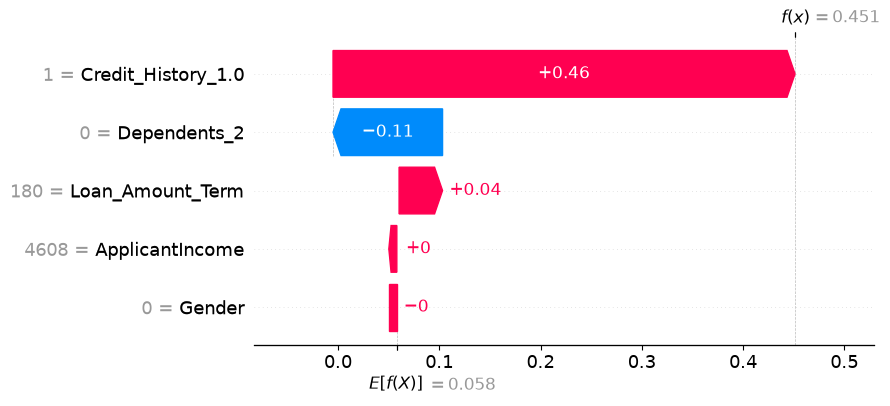

In [52]:
# Ver cómo decidió el algoritmo para la décima prueba
instance_index = 9
shap.waterfall_plot(shap.Explanation(values=shap_values[instance_index], 
                                     base_values=explainer.expected_value, 
                                     data=X_test.iloc[instance_index], 
                                     feature_names=X_test.columns.tolist()))


Índice con predicción negativa encontrado: 12


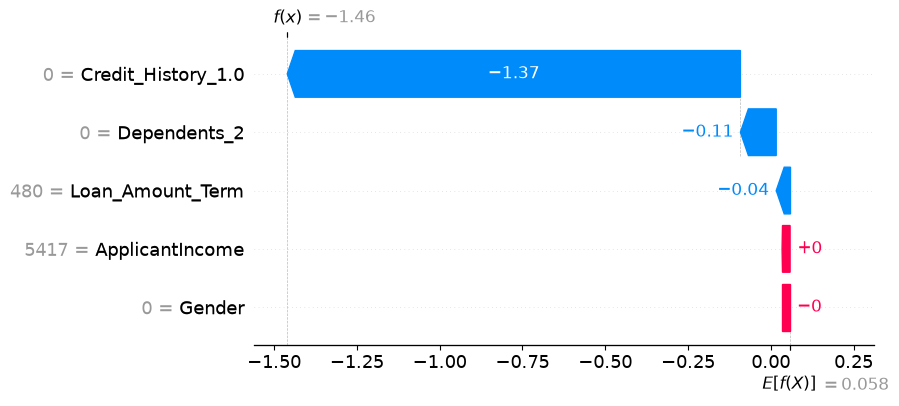

In [53]:
## Encontrar una predicción negativa

# Suponiendo que ya has calculado tus shap_values y explainer.expected_value

# Calcular la predicción final a partir de los valores SHAP
# f(x) = base_value + sum(shap_values)
predicted_values = explainer.expected_value + shap_values.sum(axis=1)

# Encontrar el índice de una instancia cuya predicción sea "negativa"
# Consideramos "negativa" si la predicción es menor que el valor base o un umbral específico (ej. 0.5 para clasificación)

# Ejemplo para encontrar un índice con predicción menor que el valor esperado:
negative_prediction_indices = [i for i, pred in enumerate(y2) if pred < explainer.expected_value]

if negative_prediction_indices:
    # Seleccionar el primer índice encontrado
    instance_index = negative_prediction_indices[0]
    print(f"Índice con predicción negativa encontrado: {instance_index}")
    
    # Generar el gráfico waterfall para este índice
    shap.waterfall_plot(shap.Explanation(
        values=shap_values[instance_index],
        base_values=explainer.expected_value,
        data=X_test.iloc[instance_index],
        feature_names=X_test.columns.tolist()
    ))
else:
    print("No se encontraron instancias con predicción menor que el valor esperado en X_test.")


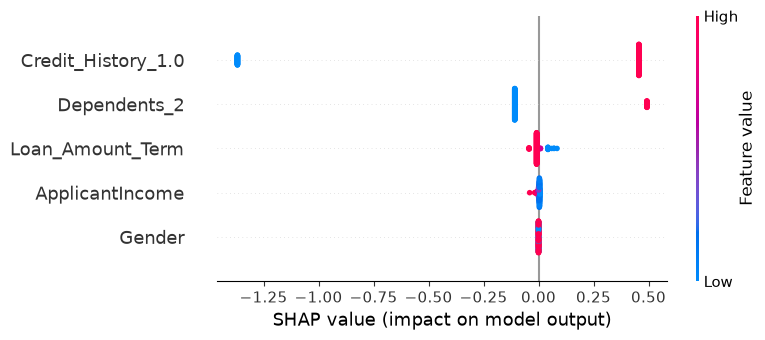

In [54]:
# Summary plot (beeswarm plot)
shap.summary_plot(shap_values, X_test, feature_names=X_test.columns.tolist())

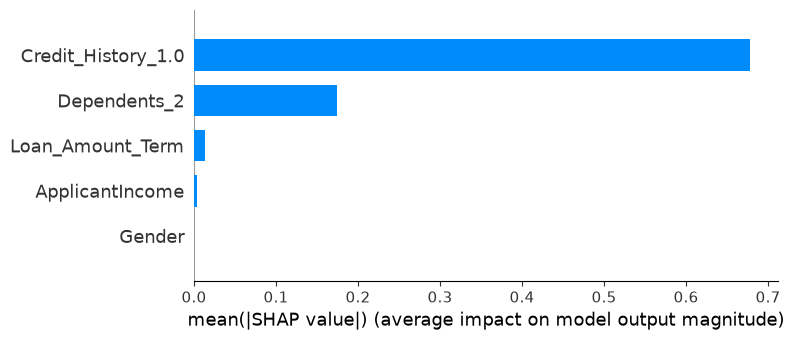

In [55]:
# Bar plot of mean absolute SHAP values (feature importance)
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=X_test.columns.tolist())

#### Interpretación del modelo mediante SHAP

- Credit_History tiene un impacto positivo muy alto. Es el predictor más importante. Un historial crediticio limpio aumenta fuertemente la probabilidad de aprobación.
- Tener al menos dos personas dependientes parece también ser importante.
- Ligeramente aportan a la predicción el Loan_Amount_Term y el Applicant Income.


### <font color='red'> Despliegue </font>



##### Usar el modelo como filtro preliminar. Aprobar automáticamente los casos con probabilidad mayor a 0.8. Los demás a revisión manual.
##### Reentrenar cada 6 meses. Agregar más variables financieras.
##### Evitar usar atributos sensibles como criterios decisivos, ya que puede generar sesgos.

In [56]:
# Simulación didáctica:
# estos umbrales no han sido optimizados ni validados para uso operativo.

y_proba = model.predict_proba(X_test)[:, 1]

# Aprobaciones automáticas
auto_approve = X_test[y_proba > 0.6]

# Revisión manual
review = X_test[(y_proba >= 0.4) & (y_proba <= 0.6)]

# Rechazos directos
reject = X_test[y_proba < 0.4]


In [57]:
auto_approve

,Gender,ApplicantIncome,Loan_Amount_Term,Dependents_2,Credit_History_1.0
Loan_ID,,,,,
LP001508,1,11757,180.0,1,1
LP002741,0,4608,180.0,0,1
LP001836,0,3427,360.0,1,1
LP001915,1,2301,180.0,1,1
LP001199,1,3357,360.0,1,1
LP001940,1,3153,360.0,1,1
LP001572,1,9323,180.0,0,1
LP002543,1,8333,360.0,1,1
LP002768,1,3358,36.0,0,1


In [58]:
review

,Gender,ApplicantIncome,Loan_Amount_Term,Dependents_2,Credit_History_1.0
Loan_ID,,,,,
LP002387,1,2425,360.0,0,1
LP002337,0,2995,360.0,0,1
LP002692,1,5677,360.0,0,1
LP002582,0,17263,360.0,0,1
LP001760,1,4758,480.0,0,1
...,...,...,...,...,...
LP002515,1,3450,360.0,0,1
LP001698,1,3975,360.0,0,1
LP002603,0,645,480.0,0,1


In [59]:
reject

,Gender,ApplicantIncome,Loan_Amount_Term,Dependents_2,Credit_History_1.0
Loan_ID,,,,,
LP001945,0,5417,480.0,0,0
LP002560,1,2699,360.0,0,0
LP002113,0,1830,360.0,0,0
LP001146,0,2645,360.0,0,0
LP001938,1,4400,360.0,1,0
LP002723,1,3588,360.0,1,0
LP001732,1,5000,360.0,1,0
LP002036,1,2058,360.0,0,0
LP001528,1,6277,360.0,0,0
